# Lab: Transfer Learning và Data Augmentation

Bài lab hoàn chỉnh để thực hiện trên Google Colab với tất cả code cần thiết.

## Thông tin Lab
- **Thời gian**: 3 tiếng
- **Môi trường**: Google Colab với GPU — nhớ chọn `Runtime > Change runtime type > T4 GPU` trước khi chạy
- **Dataset**: Oxford Flowers-17 dataset (~80 ảnh/loài, 17 loài hoa)
- **Mục tiêu**: So sánh Feature Extractor và Fine Tuning

> **Lưu ý:** So với bản gốc, notebook này đã sửa vài chỗ bug (biến `X_train`/`X_test` chưa được định nghĩa ở Phase 2 và ở bài tập ResNet50 — phải dùng `X_train_ft`/`X_test_ft`) để code chạy được từ đầu đến cuối không lỗi.

## PHẦN 1: CÀI ĐẶT MÔI TRƯỜNG (15 phút)
### Bước 1: Thiết lập Google Colab

In [1]:
# Kiểm tra GPU
!nvidia-smi

Fri Sep 25 03:41:10 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 595.61                 Driver Version: 595.95         CUDA Version: 13.2     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  NVIDIA RTX 3500 Ada Gene...    On  |   00000000:01:00.0 Off |                  Off |
| N/A   54C    P3             28W /   70W |       0MiB /  12282MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

In [2]:
# Cài đặt thư viện cần thiết
!pip install imutils -q

In [3]:
# Import libraries
import tensorflow as tf
from tensorflow.keras.applications import VGG16, ResNet50
from tensorflow.keras.applications import imagenet_utils
from tensorflow.keras.preprocessing.image import img_to_array, load_img
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.layers import Dense, Dropout, Flatten, Input
from tensorflow.keras.models import Model
from tensorflow.keras.optimizers import SGD, RMSprop, Adam

from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import GridSearchCV, train_test_split
from sklearn.preprocessing import LabelEncoder, LabelBinarizer
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay

from imutils import paths

import numpy as np
import matplotlib.pyplot as plt
import random
import os
import shutil
from pathlib import Path
from PIL import Image
import requests
import tarfile

print(f"TensorFlow version: {tf.__version__}")
print(f"GPU Available: {tf.config.list_physical_devices('GPU')}")

2026-09-25 03:41:11.263353: I tensorflow/core/util/port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
2026-09-25 03:41:11.271867: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:485] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
2026-09-25 03:41:11.282489: E external/local_xla/xla/stream_executor/cuda/cuda_dnn.cc:8454] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
2026-09-25 03:41:11.285659: E external/local_xla/xla/stream_executor/cuda/cuda_blas.cc:1452] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered
2026-09-25 03:41:11.293471: I tensorflow/core/platform/cpu_feature_guar

TensorFlow version: 2.17.0
GPU Available: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


I0000 00:00:1790322073.539879    6149 cuda_executor.cc:1001] could not open file to read NUMA node: /sys/bus/pci/devices/0000:01:00.0/numa_node
Your kernel may have been built without NUMA support.
I0000 00:00:1790322073.580410    6149 cuda_executor.cc:1001] could not open file to read NUMA node: /sys/bus/pci/devices/0000:01:00.0/numa_node
Your kernel may have been built without NUMA support.
I0000 00:00:1790322073.580465    6149 cuda_executor.cc:1001] could not open file to read NUMA node: /sys/bus/pci/devices/0000:01:00.0/numa_node
Your kernel may have been built without NUMA support.


### Bước 2: Tải và tổ chức dataset

In [4]:
def download_and_organize_flowers17():
    # URL của Oxford Flowers-17 dataset
    dataset_url = "http://www.robots.ox.ac.uk/~vgg/data/flowers/17/17flowers.tgz"

    # Tải dataset nếu chưa có
    if not os.path.exists("17flowers.tgz"):
        print("Đang tải Oxford Flowers-17 dataset...")
        response = requests.get(dataset_url, stream=True)
        with open("17flowers.tgz", "wb") as f:
            for chunk in response.iter_content(chunk_size=8192):
                f.write(chunk)
        print("Tải hoàn tất!")

    # Giải nén dataset
    if not os.path.exists("jpg"):
        print("Đang giải nén dataset...")
        with tarfile.open("17flowers.tgz", "r:gz") as tar:
            tar.extractall()
        print("Giải nén hoàn tất!")

    # Tạo cấu trúc thư mục cho dataset
    dataset_path = Path("dataset")
    dataset_path.mkdir(exist_ok=True)

    # Danh sách tên các loài hoa theo thứ tự trong dataset
    flower_names = [
        'daffodil', 'snowdrop', 'lilyvalley', 'bluebell', 'crocus',
        'iris', 'tigerlily', 'tulip', 'fritillary', 'sunflower',
        'daisy', 'coltsfoot', 'dandelion', 'cowslip', 'buttercup',
        'windflower', 'pansy'
    ]

    # Tạo thư mục cho mỗi loài hoa
    for flower in flower_names:
        (dataset_path / flower).mkdir(exist_ok=True)

    # Tổ chức ảnh theo class (mỗi class có 80 ảnh)
    jpg_path = Path("jpg")
    if jpg_path.exists():
        # Lấy tất cả file ảnh và sắp xếp theo tên
        jpg_files = sorted([f for f in jpg_path.glob("*.jpg")])
        print(f"Tìm thấy {len(jpg_files)} ảnh")

        # Di chuyển ảnh vào thư mục tương ứng
        for i, img_file in enumerate(jpg_files):
            class_idx = i // 80  # Mỗi class có 80 ảnh
            if class_idx < len(flower_names):
                flower_name = flower_names[class_idx]
                dst_path = dataset_path / flower_name / img_file.name
                # Copy file thay vì move để tránh lỗi
                shutil.copy2(str(img_file), str(dst_path))

        print(f"Đã tổ chức {len(jpg_files)} ảnh vào {len(flower_names)} classes")
    else:
        print("Không tìm thấy thư mục 'jpg'. Kiểm tra lại việc giải nén.")

    return flower_names

# Chạy function để tải và tổ chức dataset
flower_names = download_and_organize_flowers17()

# Kiểm tra kết quả
print("\nKiểm tra dataset:")
for flower in flower_names:
    count = len(list(Path(f"dataset/{flower}").glob("*.jpg")))
    print(f"{flower}: {count} ảnh")

# Tổng số ảnh
total_images = sum(len(list(Path(f"dataset/{flower}").glob("*.jpg"))) for flower in flower_names)
print(f"\nTổng số ảnh: {total_images}")

Đang tải Oxford Flowers-17 dataset...
Tải hoàn tất!
Đang giải nén dataset...
Giải nén hoàn tất!
Tìm thấy 1360 ảnh
Đã tổ chức 1360 ảnh vào 17 classes

Kiểm tra dataset:
daffodil: 80 ảnh
snowdrop: 80 ảnh
lilyvalley: 80 ảnh
bluebell: 80 ảnh
crocus: 80 ảnh
iris: 80 ảnh
tigerlily: 80 ảnh
tulip: 80 ảnh
fritillary: 80 ảnh
sunflower: 80 ảnh
daisy: 80 ảnh
coltsfoot: 80 ảnh
dandelion: 80 ảnh
cowslip: 80 ảnh
buttercup: 80 ảnh
windflower: 80 ảnh
pansy: 80 ảnh

Tổng số ảnh: 1360


## PHẦN 2: FEATURE EXTRACTOR (45 phút)
### Bước 1: Chuẩn bị dữ liệu

In [5]:
# Lấy đường dẫn ảnh
image_paths = list(paths.list_images('dataset/'))
random.shuffle(image_paths)

# Trích xuất labels từ đường dẫn
labels = [p.split(os.path.sep)[-2] for p in image_paths]

# Encode labels
le = LabelEncoder()
labels = le.fit_transform(labels)

print(f"Số lượng ảnh: {len(image_paths)}")
print(f"Số lượng classes: {len(np.unique(labels))}")
print(f"Classes: {le.classes_}")

Số lượng ảnh: 1360
Số lượng classes: 17
Classes: ['bluebell' 'buttercup' 'coltsfoot' 'cowslip' 'crocus' 'daffodil' 'daisy'
 'dandelion' 'fritillary' 'iris' 'lilyvalley' 'pansy' 'snowdrop'
 'sunflower' 'tigerlily' 'tulip' 'windflower']


### Bước 2: Load pre-trained VGG16

In [6]:
# Load VGG16 không bao gồm top layers
print("[INFO] Loading VGG16...")
model = VGG16(weights='imagenet', include_top=False)

# Hiển thị kiến trúc
model.summary()

[INFO] Loading VGG16...


I0000 00:00:1790322091.135364    6149 cuda_executor.cc:1001] could not open file to read NUMA node: /sys/bus/pci/devices/0000:01:00.0/numa_node
Your kernel may have been built without NUMA support.
I0000 00:00:1790322091.135433    6149 cuda_executor.cc:1001] could not open file to read NUMA node: /sys/bus/pci/devices/0000:01:00.0/numa_node
Your kernel may have been built without NUMA support.
I0000 00:00:1790322091.135451    6149 cuda_executor.cc:1001] could not open file to read NUMA node: /sys/bus/pci/devices/0000:01:00.0/numa_node
Your kernel may have been built without NUMA support.
I0000 00:00:1790322092.642141    6149 cuda_executor.cc:1001] could not open file to read NUMA node: /sys/bus/pci/devices/0000:01:00.0/numa_node
Your kernel may have been built without NUMA support.
I0000 00:00:1790322092.642196    6149 cuda_executor.cc:1001] could not open file to read NUMA node: /sys/bus/pci/devices/0000:01:00.0/numa_node
Your kernel may have been built without NUMA support.
2026-09-25

58889256/58889256 ━━━━━━━━━━━━━━━━━━━━ 6s 0us/step


Model: "vgg16"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, None, None, 3)  │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block1_conv1 (Conv2D)           │ (None, None, None, 64) │         1,792 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block1_conv2 (Conv2D)           │ (None, None, None, 64) │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block1_pool (MaxPooling2D)      │ (None, None, None, 64) │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_conv1 (Conv2D)           │ (None, None, None,     │        73,856 │
│                                 │ 128)                   │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_conv2 (Conv2D)           │ (None, None, None,     │       147,584 │
│                                 │ 128)                   │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_pool (MaxPooling2D)      │ (None, None, None,     │             0 │
│                                 │ 128)                   │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_conv1 (Conv2D)           │ (None, None, None,     │       295,168 │
│                                 │ 256)                   │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_conv2 (Conv2D)           │ (None, None, None,     │       590,080 │
│                                 │ 256)                   │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_conv3 (Conv2D)           │ (None, None, None,     │       590,080 │
│                                 │ 256)                   │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_pool (MaxPooling2D)      │ (None, None, None,     │             0 │
│                                 │ 256)                   │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_conv1 (Conv2D)           │ (None, None, None,     │     1,180,160 │
│                                 │ 512)                   │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_conv2 (Conv2D)           │ (None, None, None,     │     2,359,808 │
│                                 │ 512)                   │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_conv3 (Conv2D)           │ (None, None, None,     │     2,359,808 │
│                                 │ 512)                   │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_pool (MaxPooling2D)      │ (None, None, None,     │             0 │
│                                 │ 512)                   │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_conv1 (Conv2D)           │ (None, None, None,     │     2,359,808 │
│                                 │ 512)                   │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_conv2 (Conv2D)           │ (None, None, None,     │     2,359,808 │
│                                 │ 512)                   │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_conv3 (Conv2D)           │ (None, None, None,     │     2,359,808 │
│                                 │ 512)                   │             

 Total params: 14,714,688 (56.13 MB)

 Trainable params: 14,714,688 (56.13 MB)

 Non-trainable params: 0 (0.00 B)

### Bước 3: Trích xuất features

In [7]:
def load_and_preprocess_image(image_path):
    image = load_img(image_path, target_size=(224, 224))
    image = img_to_array(image)
    image = np.expand_dims(image, axis=0)
    image = imagenet_utils.preprocess_input(image)
    return image

# Trích xuất features từ tất cả ảnh
print("[INFO] Extracting features...")
features = []
for (i, image_path) in enumerate(image_paths):
    if i % 100 == 0:
        print(f"Processed {i}/{len(image_paths)} images")
    image = load_and_preprocess_image(image_path)
    feature = model.predict(image, verbose=0)
    features.append(feature)

# Chuyển đổi thành numpy array và flatten
features = np.array(features)
features = features.reshape((features.shape[0], 7 * 7 * 512))
print(f"Features shape: {features.shape}")

[INFO] Extracting features...
Processed 0/1360 images


I0000 00:00:1790322100.035905    6569 service.cc:146] XLA service 0x7a6500003c70 initialized for platform CUDA (this does not guarantee that XLA will be used). Devices:
I0000 00:00:1790322100.035936    6569 service.cc:154]   StreamExecutor device (0): NVIDIA RTX 3500 Ada Generation Laptop GPU, Compute Capability 8.9
2026-09-25 03:41:40.046949: I tensorflow/compiler/mlir/tensorflow/utils/dump_mlir_util.cc:268] disabling MLIR crash reproducer, set env var `MLIR_CRASH_REPRODUCER_DIRECTORY` to enable.
2026-09-25 03:41:40.107293: I external/local_xla/xla/stream_executor/cuda/cuda_dnn.cc:531] Loaded cuDNN version 8907
I0000 00:00:1790322101.469550    6569 device_compiler.h:188] Compiled cluster using XLA!  This line is logged at most once for the lifetime of the process.


Processed 100/1360 images
Processed 200/1360 images
Processed 300/1360 images
Processed 400/1360 images
Processed 500/1360 images
Processed 600/1360 images
Processed 700/1360 images
Processed 800/1360 images
Processed 900/1360 images
Processed 1000/1360 images
Processed 1100/1360 images
Processed 1200/1360 images
Processed 1300/1360 images
Features shape: (1360, 25088)


### Bước 4: Train classifier

In [8]:
# Chia train/test cho FEATURE EXTRACTOR
X_train_fe, X_test_fe, y_train_fe, y_test_fe = train_test_split(
    features, labels, test_size=0.2, random_state=42, stratify=labels
)

print("[INFO] Training classifier (Feature Extractor)...")
params = {'C': [0.1, 1.0, 10.0, 100.0]}
model_lr = GridSearchCV(LogisticRegression(max_iter=1000), params, cv=3)
model_lr.fit(X_train_fe, y_train_fe)
print(f"Best parameters: {model_lr.best_params_}")

# Đánh giá FE trên test set của FE
predictions_fe = model_lr.predict(X_test_fe)
print("\n[RESULTS] Feature Extractor:")
print(classification_report(y_test_fe, predictions_fe, target_names=le.classes_))

[INFO] Training classifier (Feature Extractor)...
Best parameters: {'C': 0.1}

[RESULTS] Feature Extractor:
              precision    recall  f1-score   support

    bluebell       0.94      0.94      0.94        16
   buttercup       1.00      0.75      0.86        16
   coltsfoot       1.00      0.81      0.90        16
     cowslip       0.50      0.88      0.64        16
      crocus       0.93      0.88      0.90        16
    daffodil       0.76      0.81      0.79        16
       daisy       0.88      0.94      0.91        16
   dandelion       0.93      0.88      0.90        16
  fritillary       0.94      1.00      0.97        16
        iris       0.94      0.94      0.94        16
  lilyvalley       0.76      0.81      0.79        16
       pansy       0.94      0.94      0.94        16
    snowdrop       0.93      0.81      0.87        16
   sunflower       0.94      1.00      0.97        16
   tigerlily       1.00      1.00      1.00        16
       tulip       0.92    

## PHẦN 3: FINE TUNING (60 phút)
### Bước 1: Chuẩn bị dữ liệu cho Deep Learning

In [9]:
def load_images_and_labels():
    images = []
    labels = []
    for image_path in image_paths:
        # Load ảnh
        image = load_img(image_path, target_size=(224, 224))
        image = img_to_array(image)
        image = imagenet_utils.preprocess_input(image)

        # Extract label
        label = image_path.split(os.path.sep)[-2]
        images.append(image)
        labels.append(label)
    return np.array(images), labels

print("[INFO] Loading images for fine-tuning...")
images, label_names = load_images_and_labels()

# Encode labels cho fine-tuning
le_ft = LabelEncoder()
labels_encoded = le_ft.fit_transform(label_names)

# One-hot encoding
lb = LabelBinarizer()
labels_onehot = lb.fit_transform(labels_encoded)

print(f"Images shape: {images.shape}")
print(f"Labels shape: {labels_onehot.shape}")

[INFO] Loading images for fine-tuning...
Images shape: (1360, 224, 224, 3)
Labels shape: (1360, 17)


### Bước 2: Xây dựng model Fine Tuning

In [10]:
# Load VGG16 với input tensor
base_model = VGG16(weights='imagenet', include_top=False,
                    input_tensor=Input(shape=(224, 224, 3)))

# Thêm classification head
head_model = base_model.output
head_model = Flatten(name="flatten")(head_model)
head_model = Dense(256, activation="relu")(head_model)
head_model = Dropout(0.5)(head_model)
head_model = Dense(len(le_ft.classes_), activation="softmax")(head_model)

# Tạo model hoàn chỉnh
model_ft = Model(inputs=base_model.input, outputs=head_model)

print(f"Total layers: {len(model_ft.layers)}")
print(f"Base model layers: {len(base_model.layers)}")

Total layers: 23
Base model layers: 19


### Bước 3: Chia dữ liệu và setup augmentation

In [11]:
# Chia train/test cho FINE-TUNING
X_train_ft, X_test_ft, y_train_ft, y_test_ft = train_test_split(
    images, labels_onehot, test_size=0.2, random_state=42
)

print(f"Training set: {X_train_ft.shape}")
print(f"Test set: {X_test_ft.shape}")

# Data augmentation
train_aug = ImageDataGenerator(
    rescale=1./255,
    rotation_range=30,
    width_shift_range=0.1,
    height_shift_range=0.1,
    shear_range=0.2,
    zoom_range=0.2,
    horizontal_flip=True,
    fill_mode="nearest"
)

test_aug = ImageDataGenerator(rescale=1./255)

Training set: (1088, 224, 224, 3)
Test set: (272, 224, 224, 3)


### Bước 4: Phase 1 - Warm up head

In [12]:
# Phase 1: Freeze base model
print("[INFO] Phase 1: Training head only...")
for layer in base_model.layers:
    layer.trainable = False

# Compile model
opt = RMSprop(learning_rate=0.001)
model_ft.compile(optimizer=opt, loss="categorical_crossentropy", metrics=["accuracy"])

# Train
EPOCHS_PHASE1 = 25
history1 = model_ft.fit(
    train_aug.flow(X_train_ft, y_train_ft, batch_size=32),
    steps_per_epoch=len(X_train_ft) // 32,
    validation_data=test_aug.flow(X_test_ft, y_test_ft, batch_size=32),
    validation_steps=len(X_test_ft) // 32,
    epochs=EPOCHS_PHASE1,
    verbose=1
)

[INFO] Phase 1: Training head only...
Epoch 1/25
34/34 ━━━━━━━━━━━━━━━━━━━━ 18s 189ms/step - accuracy: 0.1691 - loss: 4.6380 - val_accuracy: 0.2930 - val_loss: 2.3250
Epoch 2/25
34/34 ━━━━━━━━━━━━━━━━━━━━ 6s 164ms/step - accuracy: 0.3134 - loss: 2.2240 - val_accuracy: 0.6367 - val_loss: 1.3589
Epoch 3/25
34/34 ━━━━━━━━━━━━━━━━━━━━ 6s 166ms/step - accuracy: 0.4118 - loss: 1.7882 - val_accuracy: 0.6211 - val_loss: 1.2183
Epoch 4/25
34/34 ━━━━━━━━━━━━━━━━━━━━ 7s 195ms/step - accuracy: 0.4660 - loss: 1.5928 - val_accuracy: 0.6875 - val_loss: 1.0444
Epoch 5/25
34/34 ━━━━━━━━━━━━━━━━━━━━ 6s 166ms/step - accuracy: 0.5478 - loss: 1.4022 - val_accuracy: 0.7773 - val_loss: 0.7790
Epoch 6/25
34/34 ━━━━━━━━━━━━━━━━━━━━ 6s 167ms/step - accuracy: 0.5653 - loss: 1.3230 - val_accuracy: 0.8281 - val_loss: 0.6953
Epoch 7/25
34/34 ━━━━━━━━━━━━━━━━━━━━ 6s 165ms/step - accuracy: 0.6048 - loss: 1.2102 - val_accuracy: 0.8281 - val_loss: 0.6073
Epoch 8/25
34/34 ━━━━━━━━━━━━━━━━━━━━ 6s 164ms/step - accuracy: 0

### Bước 5: Phase 2 - Fine tune

> Đã sửa: bản gốc dùng `X_train`, `y_train`, `X_test`, `y_test` (chưa từng được định nghĩa) — ở đây dùng đúng `X_train_ft`, `y_train_ft`, `X_test_ft`, `y_test_ft` đã tạo ở Bước 3.

In [13]:
# Phase 2: Unfreeze và fine-tune
print("[INFO] Phase 2: Fine-tuning...")

# Unfreeze một số layers cuối
for layer in base_model.layers[15:]:
    layer.trainable = True

# Compile lại với learning rate thấp hơn
opt = SGD(learning_rate=0.001 / 10)
model_ft.compile(optimizer=opt, loss="categorical_crossentropy", metrics=["accuracy"])

# Continue training
EPOCHS_PHASE2 = 25
history2 = model_ft.fit(
    train_aug.flow(X_train_ft, y_train_ft, batch_size=32),
    steps_per_epoch=len(X_train_ft) // 32,
    validation_data=test_aug.flow(X_test_ft, y_test_ft, batch_size=32),
    validation_steps=len(X_test_ft) // 32,
    epochs=EPOCHS_PHASE2,
    verbose=1
)

[INFO] Phase 2: Fine-tuning...
Epoch 1/25
34/34 ━━━━━━━━━━━━━━━━━━━━ 10s 219ms/step - accuracy: 0.7941 - loss: 0.5999 - val_accuracy: 0.8750 - val_loss: 0.3427
Epoch 2/25
34/34 ━━━━━━━━━━━━━━━━━━━━ 6s 173ms/step - accuracy: 0.7987 - loss: 0.5947 - val_accuracy: 0.8906 - val_loss: 0.3282
Epoch 3/25
34/34 ━━━━━━━━━━━━━━━━━━━━ 6s 171ms/step - accuracy: 0.8134 - loss: 0.5162 - val_accuracy: 0.9023 - val_loss: 0.3197
Epoch 4/25
34/34 ━━━━━━━━━━━━━━━━━━━━ 6s 174ms/step - accuracy: 0.8373 - loss: 0.4900 - val_accuracy: 0.9062 - val_loss: 0.3018
Epoch 5/25
34/34 ━━━━━━━━━━━━━━━━━━━━ 6s 173ms/step - accuracy: 0.8281 - loss: 0.5113 - val_accuracy: 0.8945 - val_loss: 0.3089
Epoch 6/25
34/34 ━━━━━━━━━━━━━━━━━━━━ 6s 171ms/step - accuracy: 0.8392 - loss: 0.4608 - val_accuracy: 0.9102 - val_loss: 0.2836
Epoch 7/25
34/34 ━━━━━━━━━━━━━━━━━━━━ 7s 205ms/step - accuracy: 0.8355 - loss: 0.4632 - val_accuracy: 0.9102 - val_loss: 0.2811
Epoch 8/25
34/34 ━━━━━━━━━━━━━━━━━━━━ 6s 164ms/step - accuracy: 0.8612 -

## PHẦN 4: SO SÁNH VÀ ĐÁNH GIÁ (30 phút)
### Bước 1: Vẽ learning curves

> Cải tiến nhỏ so với bản gốc: nối `history1` (Phase 1) và `history2` (Phase 2) lại thành một đường cong liên tục, có vạch đánh dấu thời điểm bắt đầu fine-tune, thay vì chỉ vẽ mỗi `history1`.

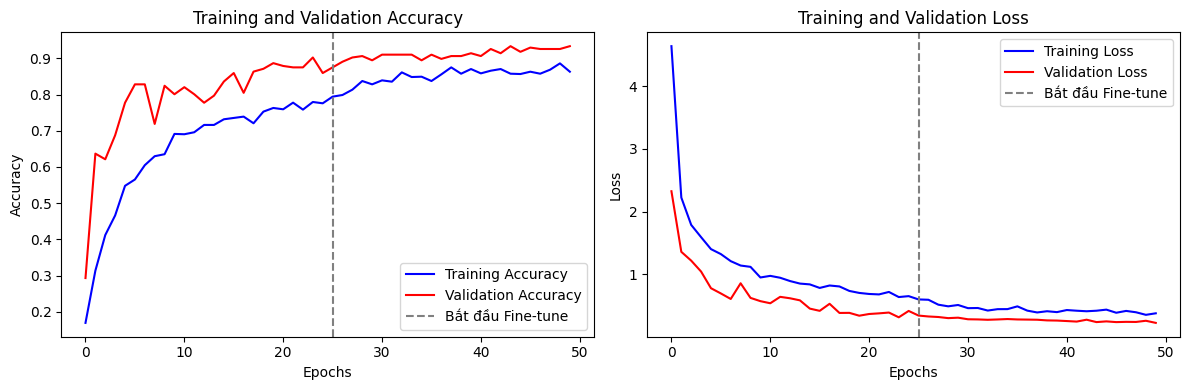

In [14]:
def plot_training_history(history1, history2=None):
    # Combine Phase 1 + Phase 2 (nếu có) thành một đường cong liên tục
    acc = history1.history['accuracy']
    val_acc = history1.history['val_accuracy']
    loss = history1.history['loss']
    val_loss = history1.history['val_loss']
    fine_tune_start = len(acc)

    if history2 is not None:
        acc += history2.history['accuracy']
        val_acc += history2.history['val_accuracy']
        loss += history2.history['loss']
        val_loss += history2.history['val_loss']

    epochs = range(len(acc))

    plt.figure(figsize=(12, 4))

    # Accuracy
    plt.subplot(1, 2, 1)
    plt.plot(epochs, acc, 'b-', label='Training Accuracy')
    plt.plot(epochs, val_acc, 'r-', label='Validation Accuracy')
    if history2 is not None:
        plt.axvline(x=fine_tune_start, color='gray', linestyle='--', label='Bắt đầu Fine-tune')
    plt.title('Training and Validation Accuracy')
    plt.xlabel('Epochs')
    plt.ylabel('Accuracy')
    plt.legend()

    # Loss
    plt.subplot(1, 2, 2)
    plt.plot(epochs, loss, 'b-', label='Training Loss')
    plt.plot(epochs, val_loss, 'r-', label='Validation Loss')
    if history2 is not None:
        plt.axvline(x=fine_tune_start, color='gray', linestyle='--', label='Bắt đầu Fine-tune')
    plt.title('Training and Validation Loss')
    plt.xlabel('Epochs')
    plt.ylabel('Loss')
    plt.legend()

    plt.tight_layout()
    plt.show()

plot_training_history(history1, history2)

### Bước 2: Đánh giá final model

[INFO] Evaluating fine-tuned model...
9/9 ━━━━━━━━━━━━━━━━━━━━ 6s 673ms/step

[RESULTS] Fine Tuning:
              precision    recall  f1-score   support

    bluebell       0.83      0.77      0.80        13
   buttercup       0.94      0.89      0.91        18
   coltsfoot       0.84      1.00      0.91        16
     cowslip       0.94      1.00      0.97        17
      crocus       1.00      1.00      1.00        15
    daffodil       0.85      1.00      0.92        11
       daisy       1.00      0.93      0.97        15
   dandelion       1.00      0.86      0.93        22
  fritillary       1.00      1.00      1.00         9
        iris       1.00      0.75      0.86        16
  lilyvalley       0.94      0.81      0.87        21
       pansy       0.94      1.00      0.97        15
    snowdrop       0.79      1.00      0.88        11
   sunflower       0.95      1.00      0.98        21
   tigerlily       0.89      1.00      0.94        16
       tulip       0.89      0.94 

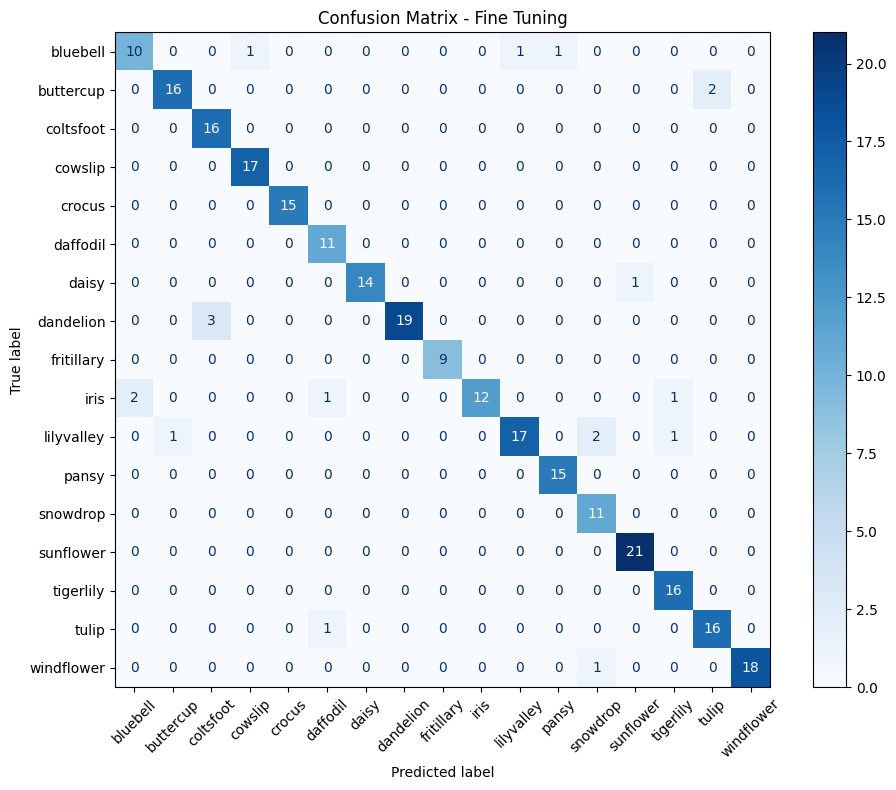

In [15]:
# Predict trên test set
print("[INFO] Evaluating fine-tuned model...")
predictions = model_ft.predict(test_aug.flow(X_test_ft, y_test_ft, batch_size=32, shuffle=False))
predictions = np.argmax(predictions, axis=1)
y_test_labels = np.argmax(y_test_ft, axis=1)

# Classification report
print("\n[RESULTS] Fine Tuning:")
print(classification_report(y_test_labels, predictions, target_names=le_ft.classes_))

# Confusion matrix
cm = confusion_matrix(y_test_labels, predictions)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=le_ft.classes_)
fig, ax = plt.subplots(figsize=(10, 8))
disp.plot(ax=ax, cmap='Blues', xticks_rotation=45)
plt.title("Confusion Matrix - Fine Tuning")
plt.tight_layout()
plt.show()

### Bước 3: So sánh kết quả

In [16]:
print("[INFO] Đang so sánh kết quả giữa Feature Extractor và Fine Tuning...")

# 1) Accuracy của FEATURE EXTRACTOR trên test set FE
fe_accuracy = model_lr.score(X_test_fe, y_test_fe)

# 2) Accuracy của FINE-TUNING trên test set FT
#    - Dùng generator với rescale giống lúc validation
test_ft_gen = test_aug.flow(X_test_ft, y_test_ft, batch_size=32, shuffle=False)
#    - Tránh steps=0 khi test ít mẫu
steps = max(1, len(X_test_ft) // 32)
ft_eval = model_ft.evaluate(test_ft_gen, steps=steps, verbose=0)
ft_accuracy = ft_eval[1]  # metrics=["accuracy"] => index 1

# 3) In bảng so sánh
print("\n" + "=" * 50)
print("BẢNG SO SÁNH KẾT QUẢ (đánh giá trên TEST của từng pipeline)")
print("=" * 50)
print(f"Feature Extractor Accuracy (test FE): {fe_accuracy:.4f}")
print(f"Fine Tuning Accuracy (test FT): {ft_accuracy:.4f}")
print(f"Improvement (FT - FE): {ft_accuracy - fe_accuracy:+.4f}")
print("=" * 50)

[INFO] Đang so sánh kết quả giữa Feature Extractor và Fine Tuning...

BẢNG SO SÁNH KẾT QUẢ (đánh giá trên TEST của từng pipeline)
Feature Extractor Accuracy (test FE): 0.8787
Fine Tuning Accuracy (test FT): 0.9297
Improvement (FT - FE): +0.0510


## PHẦN 5: THỰC NGHIỆM NÂNG CAO (30 phút)
### Thí nghiệm 1: Ảnh hưởng của Data Augmentation

In [17]:
# Train model không có augmentation
print("[INFO] Training without augmentation...")

# Chỉ rescale, không augment
no_aug = ImageDataGenerator(rescale=1./255)

# Reset model (lưu ý: dùng chung layers/weights với base_model + head_model đã train ở trên,
# đây là cách rút gọn cho mục đích so sánh nhanh trong lab)
model_no_aug = Model(inputs=base_model.input, outputs=head_model)
for layer in base_model.layers:
    layer.trainable = False

model_no_aug.compile(optimizer=RMSprop(0.001), loss="categorical_crossentropy",
                      metrics=["accuracy"])

# Train
history_no_aug = model_no_aug.fit(
    no_aug.flow(X_train_ft, y_train_ft, batch_size=32),
    steps_per_epoch=len(X_train_ft) // 32,
    validation_data=no_aug.flow(X_test_ft, y_test_ft, batch_size=32),
    validation_steps=len(X_test_ft) // 32,
    epochs=15,
    verbose=1
)

# So sánh
print("With Augmentation - Final Val Accuracy:", max(history1.history['val_accuracy']))
print("Without Augmentation - Final Val Accuracy:", max(history_no_aug.history['val_accuracy']))

[INFO] Training without augmentation...
Epoch 1/15
34/34 ━━━━━━━━━━━━━━━━━━━━ 5s 102ms/step - accuracy: 0.8300 - loss: 0.4844 - val_accuracy: 0.9180 - val_loss: 0.2782
Epoch 2/15
34/34 ━━━━━━━━━━━━━━━━━━━━ 3s 90ms/step - accuracy: 0.8695 - loss: 0.3574 - val_accuracy: 0.9023 - val_loss: 0.2984
Epoch 3/15
34/34 ━━━━━━━━━━━━━━━━━━━━ 4s 126ms/step - accuracy: 0.8842 - loss: 0.3139 - val_accuracy: 0.9062 - val_loss: 0.3956
Epoch 4/15
34/34 ━━━━━━━━━━━━━━━━━━━━ 3s 85ms/step - accuracy: 0.8971 - loss: 0.3181 - val_accuracy: 0.9062 - val_loss: 0.2833
Epoch 5/15
34/34 ━━━━━━━━━━━━━━━━━━━━ 3s 85ms/step - accuracy: 0.8925 - loss: 0.3145 - val_accuracy: 0.8945 - val_loss: 0.3625
Epoch 6/15
34/34 ━━━━━━━━━━━━━━━━━━━━ 3s 84ms/step - accuracy: 0.8998 - loss: 0.2677 - val_accuracy: 0.8672 - val_loss: 0.4769
Epoch 7/15
34/34 ━━━━━━━━━━━━━━━━━━━━ 3s 84ms/step - accuracy: 0.9164 - loss: 0.2427 - val_accuracy: 0.9336 - val_loss: 0.2493
Epoch 8/15
34/34 ━━━━━━━━━━━━━━━━━━━━ 3s 85ms/step - accuracy: 0.9145

### Thí nghiệm 2: Số lượng layers unfreeze

In [18]:
# Test với số lượng layers unfreeze khác nhau
unfreeze_configs = [5, 10, 15, 20]  # Số layers cuối để unfreeze
results = {}

for n_layers in unfreeze_configs:
    print(f"[INFO] Testing with {n_layers} unfrozen layers...")

    # Reset model
    test_model = Model(inputs=base_model.input, outputs=head_model)

    # Freeze/unfreeze layers
    for layer in base_model.layers[:-n_layers]:
        layer.trainable = False
    for layer in base_model.layers[-n_layers:]:
        layer.trainable = True

    # Quick training (ít steps/epochs để so sánh nhanh, không cần train đầy đủ)
    test_model.compile(optimizer=SGD(0.0001), loss="categorical_crossentropy",
                        metrics=["accuracy"])

    history = test_model.fit(
        train_aug.flow(X_train_ft, y_train_ft, batch_size=32),
        steps_per_epoch=10,   # Ít steps để test nhanh
        validation_data=test_aug.flow(X_test_ft, y_test_ft, batch_size=32),
        validation_steps=5,
        epochs=5,
        verbose=0
    )

    results[n_layers] = max(history.history['val_accuracy'])

# Hiển thị kết quả
print("\nUnfreeze Layers vs Accuracy:")
for layers, acc in results.items():
    print(f"{layers} layers: {acc:.4f}")

[INFO] Testing with 5 unfrozen layers...


/home/xuand/miniconda3/envs/vehicle_env/lib/python3.10/site-packages/keras/src/trainers/epoch_iterator.py:116: UserWarning: Your input ran out of data; interrupting training. Make sure that your dataset or generator can generate at least `steps_per_epoch * epochs` batches. You may need to use the `.repeat()` function when building your dataset.
  self._interrupted_warning()


[INFO] Testing with 10 unfrozen layers...
[INFO] Testing with 15 unfrozen layers...
[INFO] Testing with 20 unfrozen layers...

Unfreeze Layers vs Accuracy:
5 layers: 0.9062
10 layers: 0.9312
15 layers: 0.9187
20 layers: 0.9312


**Giải thích đoạn code trên:**

Đây là một cách **hyperparameter tuning nhanh** để tìm số layers "sweet spot" cần unfreeze khi fine-tune:

1. **Thiết lập cấu hình thử nghiệm** — `unfreeze_configs = [5, 10, 15, 20]`: thử lần lượt 4 mức độ unfreeze layers cuối của backbone.
2. **Reset model mỗi lần thử** — tạo lại `test_model` từ `base_model`/`head_model` để không bị ảnh hưởng bởi trạng thái của lần chạy trước.
3. **Freeze/unfreeze theo cấu hình** — freeze các layers đầu, chỉ để `n_layers` layers cuối cùng của backbone có thể học.
4. **Learning rate rất nhỏ (`SGD(0.0001)`)** — để không phá hỏng pre-trained weights khi mở nhiều layers.
5. **Training rút gọn** (`steps_per_epoch=10`, `validation_steps=5`, `epochs=5`) — chỉ để so sánh nhanh xu hướng, không phải để lấy accuracy cuối cùng.

**Cách đọc kết quả:**
- Nếu accuracy tăng dần theo số layers unfreeze → backbone cần được "thích nghi" nhiều hơn với dataset hoa (dataset khác khá nhiều so với ImageNet).
- Nếu có "plateau" (accuracy không đổi) ở một mức nào đó → những layers bổ sung không đóng góp thêm nhiều.
- Vì chỉ chạy 5 epoch/10 step, kết quả ở đây **chỉ mang tính định hướng** — cấu hình có vẻ tốt nhất nên được train lại đầy đủ (epochs cao hơn + early stopping) để kết luận chắc chắn, và cần theo dõi validation loss để tránh overfitting khi unfreeze nhiều layers.

## PHẦN 6: BÀI TẬP VỀ NHÀ
### Nhiệm vụ 1: Thử nghiệm với backbone khác (ResNet50)

> Đã sửa: bản gốc dùng `X_train`, `y_train`, `X_test`, `y_test` (chưa được định nghĩa) — ở đây dùng đúng `X_train_ft`, `y_train_ft`, `X_test_ft`, `y_test_ft`.

In [19]:
def experiment_with_resnet50():
    # Load ResNet50
    base_model_resnet = ResNet50(weights='imagenet', include_top=False,
                                  input_tensor=Input(shape=(224, 224, 3)))

    # Thêm classification head
    head_model_resnet = base_model_resnet.output
    head_model_resnet = Flatten()(head_model_resnet)
    head_model_resnet = Dense(256, activation="relu")(head_model_resnet)
    head_model_resnet = Dropout(0.5)(head_model_resnet)
    head_model_resnet = Dense(len(le_ft.classes_), activation="softmax")(head_model_resnet)

    model_resnet = Model(inputs=base_model_resnet.input, outputs=head_model_resnet)

    # Freeze base model
    for layer in base_model_resnet.layers:
        layer.trainable = False

    model_resnet.compile(optimizer=RMSprop(0.001),
                          loss="categorical_crossentropy",
                          metrics=["accuracy"])

    # Quick training
    history_resnet = model_resnet.fit(
        train_aug.flow(X_train_ft, y_train_ft, batch_size=32),
        steps_per_epoch=20,
        validation_data=test_aug.flow(X_test_ft, y_test_ft, batch_size=32),
        validation_steps=10,
        epochs=10,
        verbose=1
    )

    return max(history_resnet.history['val_accuracy'])

# Uncomment để chạy
# resnet_accuracy = experiment_with_resnet50()
# print(f"ResNet50 Accuracy: {resnet_accuracy:.4f}")

### Nhiệm vụ 2: Test Time Augmentation (TTA)

In [20]:
def test_time_augmentation(model, image, n_augment=5):
    """
    Apply TTA to improve prediction accuracy
    """
    # Tạo augmentation generator
    tta_gen = ImageDataGenerator(
        rescale=1./255,
        rotation_range=15,
        width_shift_range=0.1,
        height_shift_range=0.1,
        horizontal_flip=True
    )

    predictions = []

    # Tạo batch từ một ảnh
    image_batch = np.expand_dims(image, axis=0)

    # Generate augmented versions
    for i, augmented_batch in enumerate(tta_gen.flow(image_batch, batch_size=1)):
        if i >= n_augment:
            break
        pred = model.predict(augmented_batch, verbose=0)
        predictions.append(pred)

    # Average predictions
    avg_prediction = np.mean(predictions, axis=0)
    return avg_prediction

# Example usage (uncomment để test)
# sample_image = X_test_ft[0]
# tta_pred = test_time_augmentation(model_ft, sample_image)
# print(f"TTA Prediction: {np.argmax(tta_pred)}")

## PHẦN 7: CÂU HỎI THẢO LUẬN

### Câu hỏi lý thuyết

**1. Trong trường hợp nào nên dùng Feature Extractor thay vì Fine Tuning?**
- Khi có ít dữ liệu training
- Khi dataset tương tự ImageNet
- Khi cần training nhanh
- Khi tài nguyên tính toán hạn chế

**2. Tại sao phải sử dụng learning rate thấp hơn khi fine-tune?**
- Để tránh phá hủy pre-trained weights
- Để learning process ổn định hơn
- Để tránh overfitting

**3. Data augmentation có thể gây hại trong trường hợp nào?**
- Khi augmentation không phù hợp với domain
- Khi có quá nhiều dữ liệu
- Khi augmentation quá mạnh làm mất đặc trưng quan trọng

### Câu hỏi thực hành

**1. Làm thế nào để chọn số lượng layers optimal để unfreeze?**
- Thử nghiệm với các số lượng khác nhau
- Quan sát validation accuracy
- Cân bằng giữa performance và training time

**2. Khi nào nên dừng training trong fine-tuning?**
- Khi validation loss bắt đầu tăng
- Khi validation accuracy không cải thiện
- Sử dụng early stopping

**3. Làm sao để detect overfitting trong quá trình training?**
- Quan sát gap giữa training và validation accuracy
- Vẽ learning curves
- Sử dụng validation metrics

### Bài tập mở rộng (khung code, tự hoàn thiện)

In [21]:
# 1. So sánh VGG16 vs ResNet50 vs MobileNetV2
def compare_backbones():
    backbones = {
        'VGG16': VGG16,
        'ResNet50': ResNet50,
        # 'MobileNetV2': MobileNetV2  # Uncomment nếu muốn test
    }
    results = {}
    for name, backbone in backbones.items():
        print(f"Testing {name}...")
        # Implement comparison logic here
        pass
    return results

# 2. Experiment với các kỹ thuật augmentation khác
def advanced_augmentation():
    # Implement mixup, cutmix, etc.
    pass

# 3. Ensemble của nhiều models
def ensemble_models(models, X_test):
    predictions = []
    for model in models:
        pred = model.predict(X_test)
        predictions.append(pred)
    # Average predictions
    ensemble_pred = np.mean(predictions, axis=0)
    return np.argmax(ensemble_pred, axis=1)